# Primeira execução e componentes

10 minutos

[Objetivos e sequência de aprendizagem](../docs/jornada.md).
Execute com o kernel Python de `.venv`.

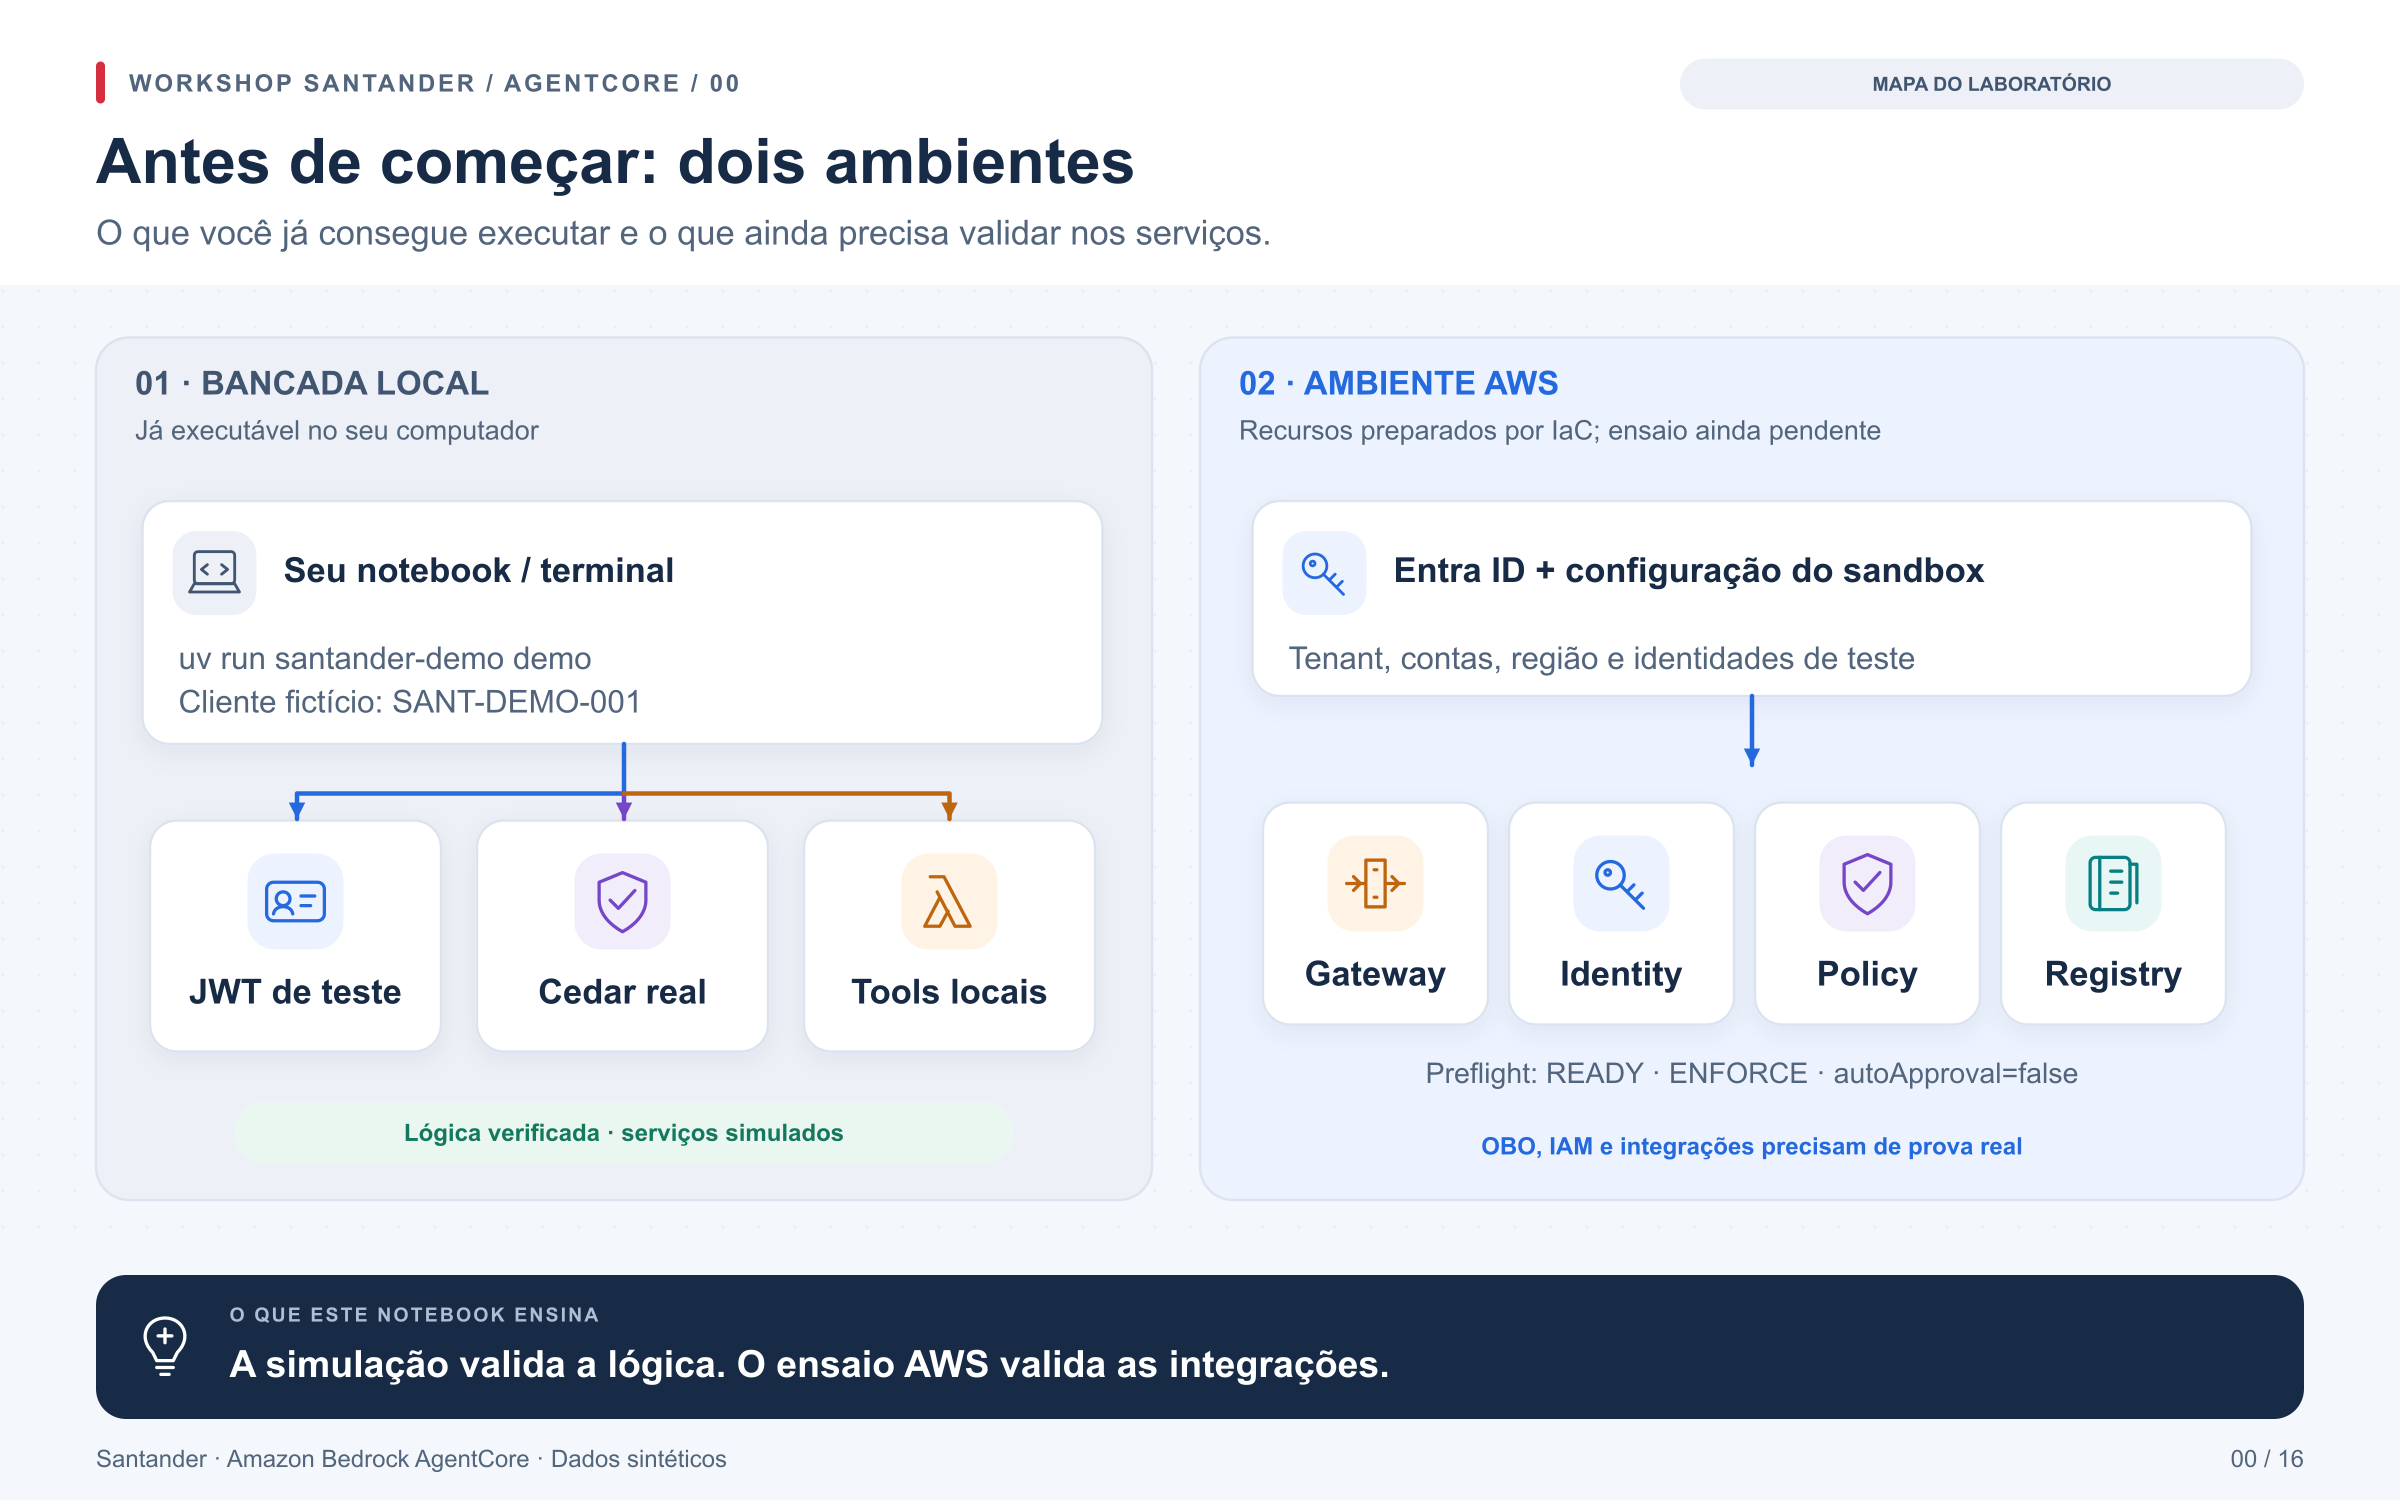

**Objetivo visual:** Saber exatamente qual ambiente está sendo usado e o que seu resultado comprova.

[Abrir PNG](../docs/diagramas/png/00_preflight.png) · [SVG editável](../docs/diagramas/svg/00_preflight.svg) · [Galeria dos notebooks](../docs/diagramas/index.html)

**Etapa 1 de 17 na jornada.** [Jornada completa](../docs/jornada.md) · [Próximo: Gateway e ferramentas](01_gateway_targets.ipynb)

## Conceitos para acompanhar este laboratório

**Preflight** é uma conferência de pré-requisitos: um recurso em `READY`
está disponível, mas esse estado não comprova uma chamada ponta a ponta.
**Runtime** hospeda o código; **Gateway** expõe ferramentas; **Identity**
gerencia identidades de workload e credenciais para outros serviços.
**Policy** decide se uma chamada é permitida; **Registry** cataloga capacidades.

**Autenticação** verifica quem apresenta a credencial e a quem ela se destina.
**Autorização** decide quais ações essa identidade pode executar. Por isso,
aceitar um JWT não significa permitir todas as ferramentas.

Leia `CloudWorkshop.preflight()` em [cloud.py](../src/santander_demo/cloud.py)
e compare suas asserções com a saída. Nesta etapa, `user_obo_verified=False`
é esperado: a troca de token será exercitada em outro notebook.

**Documentação oficial para aprofundar:**

* [Visão geral dos componentes AgentCore](https://docs.aws.amazon.com/bedrock-agentcore/latest/devguide/what-is-bedrock-agentcore.html)
* [Autenticação de entrada do Gateway](https://docs.aws.amazon.com/bedrock-agentcore/latest/devguide/gateway-inbound-auth.html)
* [Modos de aplicação de Policy](https://docs.aws.amazon.com/bedrock-agentcore/latest/devguide/policy-enforcement-modes.html)

As explicações estão em português; nomes de APIs, claims e campos permanecem como aparecem no código. As páginas oficiais podem estar em inglês.

O modo **local** usa um emissor JWT efêmero e o avaliador Cedar real. Gateway,
Registry, contas e fontes são simulados. O modo **aws** faz chamadas reais,
requer `config/local.json` e os stacks do [runbook](../docs/deploy.md).

Objetivo: observar uma chamada local e reconhecer os componentes antes de
estudar suas responsabilidades. A infraestrutura usa o pipeline do projeto.

### Preparar o ambiente deste notebook

Vamos importar os componentes do workshop, localizar a pasta do projeto e ler
`WORKSHOP_MODE`, cujo padrão é `local`. A instância `lab` reúne o emissor de
tokens de teste, o catálogo em memória, as políticas Cedar e o registro de
evidências que serão usados nas próximas células.

Se o modo for `aws`, também carregaremos `config/local.json` e inicializaremos
o cliente do ambiente configurado. Ao final, a mensagem mostrará o modo ativo;
`LOCAL_SIMULATION` indica que os resultados locais não comprovam a integração
com AWS ou Entra. Reexecutar esta célula reinicia o estado local do laboratório.

In [ ]:
import os
from pathlib import Path
from santander_demo.local import Workshop
from santander_demo.contracts import CLIENTE, DemoError

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
MODE = os.environ.get("WORKSHOP_MODE", "local")
assert MODE in {"local", "aws"}, "WORKSHOP_MODE deve ser local ou aws"
lab = Workshop()
cloud = None
if MODE == "aws":
    from santander_demo.config import Environment
    from santander_demo.cloud import CloudWorkshop
    config = Environment.load(ROOT / "config/local.json")
    cloud = CloudWorkshop(config)
print("LOCAL_SIMULATION — nenhuma prova de AWS/Entra" if MODE == "local" else "AWS — integração real")

### Conferir dependências e prontidão

Vamos exibir as versões instaladas de `boto3`, `mcp`, `cedarpy` e
`pyjwt` para identificar o ambiente de execução. No modo local,
verificaremos se as três ferramentas do laboratório estão disponíveis
e mostraremos quais componentes são simulados.

No modo AWS, `cloud.preflight()` consultará a configuração existente
e verificará Gateway e Registry em `READY`, Policy em `ENFORCE` e
autenticação configurada. Uma asserção interromperá a célula se
alguma condição não for atendida; passar aqui ainda não comprova OBO.

In [ ]:
import importlib.metadata as metadata
versions = {name: metadata.version(name) for name in ["boto3", "mcp", "cedarpy", "pyjwt"]}
print(versions)
if MODE == "aws":
    print(cloud.preflight())
else:
    assert len(lab.tools()) == 3
    print({"gateway": "simulado", "registry": "simulado", "cedar": "nativo local",
           "customer": CLIENTE, "cloud_validated": False})

**Aceite:** no modo AWS, Gateway e Registry em READY; autoApproval=false;
JWT Entra com audiência/emissor declarados; Policy em ENFORCE. Um erro encerra o
exercício. Não “corrigir” configuração via boto3.

**Para discutir:** quais contas representam origem A, hub C e domínio B?
Qual aplicação é identificada por `azp`/`appid`? A lista de usuários da demo é
uma allowlist de OIDs no tenant, não um espelho de grupos produtivos.

## Limpeza — recursos do laboratório

Os notebooks **00–06, 08, 10 e 13 compartilham o ambiente**. Remova os stacks somente
ao encerrar toda a trilha, depois de salvar as evidências.

1. Atualize `origin` com `EnableRuntime=false` pelo `scripts/deploy.py`.
2. Remova `registry`; preserve o output de `policy-draft`, se utilizado,
   antes de remover seu stack. O histórico de geração usa `Retain`.
3. Atualize `hub` com `EnableFraud=false` pelo `scripts/deploy.py`.
4. Remova `fraud-runtime`, depois `hub` e, por último, `origin`.
5. Remova os stacks `bootstrap` somente após revisar os artefatos retidos.

Para cada remoção, use o template correspondente e o **nome real do stack**
implantado. Os nomes de template acima não determinam os nomes dos stacks.
Buckets usam `Retain`; aplicações e segredos Entra seguem o Terraform que os
gerencia. O notebook 13 não é proprietário do workspace, warehouse ou grants
Databricks. Consulte o [runbook da trilha](../docs/deploy.md#9-limpeza).

**Na próxima célula**, `CLEANUP_TARGET=None` manterá a remoção desativada e
imprimirá `cloud_cleanup: NOT_RUN`. Para revisar um stack real, preencha o
alvo indicado no comentário e mantenha `CLEANUP_EXECUTE=False`. O script
`scripts/cleanup.py` consultará STS e CloudFormation, exigirá correspondência
exata entre template implantado e fonte local e mostrará o ARN, as retenções
declaradas e eventuais bloqueios. Essa preparação faz somente leituras.

Após revisar o plano e a ordem acima, copie seu ARN para
`CLEANUP_CONFIRM_STACK_ID` e habilite `CLEANUP_EXECUTE` para remover **esse
stack** pelo wrapper IaC. O script aguarda a exclusão pelo CloudFormation,
respeita `Retain` e não desativa proteções. Falhas devem ser resolvidas no
IaC. A execução padrão deste notebook não remove recursos em nuvem.

In [ ]:
import subprocess as _cleanup_subprocess
import sys as _cleanup_sys

# Preencha somente para um stack do laboratório, após encerrar a trilha:
# {"template": "TEMPLATE", "stack": "NOME_REAL", "profile": "PERFIL",
#   "account": "ID_DA_CONTA", "region": "REGIAO"}
CLEANUP_TARGET = None
CLEANUP_EXECUTE = False
CLEANUP_CONFIRM_STACK_ID = ""

if CLEANUP_TARGET is None:
    print({"cloud_cleanup": "NOT_RUN", "reason": "Nenhum stack selecionado"})
else:
    assert set(CLEANUP_TARGET) == {"template", "stack", "profile", "account", "region"}
    _cleanup_command = [
        _cleanup_sys.executable, str(ROOT / "scripts/cleanup.py"),
        "--scenario", "workshop",
    ]
    for _cleanup_key, _cleanup_value in CLEANUP_TARGET.items():
        _cleanup_command.extend(["--" + _cleanup_key, _cleanup_value])
    if CLEANUP_EXECUTE:
        assert CLEANUP_CONFIRM_STACK_ID, "Revise o plano e informe o ARN exato do stack"
        _cleanup_command.extend(["--execute", "--confirm-stack-id", CLEANUP_CONFIRM_STACK_ID])
    _cleanup_subprocess.run(_cleanup_command, cwd=ROOT, check=True)

### Limpeza — estado local do notebook

Vamos remover as variáveis de dados, tokens, clientes e configuração criadas
por este exercício. As sessões MCP abertas com `async with` já foram encerradas
ao sair de seus blocos; o cliente de controle de `cloud`, quando presente,
também será fechado. A célula verificará que os nomes listados deixaram
de existir e exibirá `cleanup_local: PASS`; ela pode ser repetida.

Os notebooks, diagramas, templates e arquivos de evidências serão preservados.
Esta limpeza remove referências do namespace; não revoga tokens nem apaga
outputs ou todas as cópias que possam existir na memória do processo.
Após salvar as evidências, limpe as saídas e encerre o kernel para terminar
a sessão. Para repetir o laboratório, recomece pela preparação do ambiente.

In [ ]:
import json as _cleanup_json

if globals().get("cloud") is not None:
    cloud.control.close()
_cleanup_names = ['CLEANUP_CONFIRM_STACK_ID', 'CLEANUP_EXECUTE', 'CLEANUP_TARGET', 'MODE',
 '_cleanup_command', '_cleanup_key', '_cleanup_subprocess', '_cleanup_sys',
 '_cleanup_value', 'cloud', 'config', 'identity', 'lab', 'token', 'versions']
_cleanup_removed = [name for name in _cleanup_names if name in globals()]
for _cleanup_name in _cleanup_names:
    globals().pop(_cleanup_name, None)
assert not any(name in globals() for name in _cleanup_names)
print(_cleanup_json.dumps({
    "cleanup_local": "PASS",
    "removed_variables": len(_cleanup_removed),
    "files": "PRESERVED",
}, ensure_ascii=False))
del _cleanup_name, _cleanup_names, _cleanup_removed, _cleanup_json